### Tiro Parabólico

Es el desplazamiento realizado por cualquier objeto cuya trayectoria describe una parábola, el cual corresponde con la trayectoria ideal de un proyectil que se mueve en un medio que presenta mínimos de resistencia durante su avance. El movimiento parabólico es un ejemplo de un movimiento realizado por un objeto en dos dimensiones o sobre un plano. Puede considerarse como la combinación de dos movimientos que son un movimiento horizontal uniforme y un movimiento vertical (Wikipedia, 2024).

$$\frac{d^2x}{dt^2} = a = -g$$

$$x(t) = -\frac{1}{2} g t^2 + V_{0}t + x_{0}$$

$$y(t) = -\frac{1}{2} g t^2 + V_{0}t + y_{0}$$

Ecuaciones de casos particulares

#### Tiro Horizontal

Posiciones
$$x = V_{0}t + x_{0}$$
$$y = -\frac{1}{2} g t^2 + V_{0}t + y_{0}$$

Tiempo para distancia máxima $(y=0)$
$$t_{max} = \sqrt{\frac{2y_{0}}{g}}$$

Distancia máxima
$$x_{max} = V_{0} t_{max} = V_{0} \sqrt{\frac{2y_{0}}{g}}$$

Velocidad final
$$V_{f} = \sqrt{V_{0}^2 + (g t_{max})^2 }$$

#### Tiros Verticales

##### Para arriba ($\theta = 90^o$)

Posiciones
$$x = 0$$
$$y = -\frac{1}{2} g t^2 + V_{0}t + y_{0}$$

Tiempo de ascenso
$$t_{ascenso} = \frac{V_{0}}{g}$$

Tiempo de vuelo total
$$t_{total} = 2t_{ascenso} =2\frac{V_{0}}{g}$$

Altura máxima
$$y_{max} = y_{0} + \frac{V_{0}^2}{2g}$$

##### Para abajo ($\theta = -90^o = 270^o$)

Posiciones
$$x = 0$$
$$y = -\frac{1}{2} g t^2 - V_{0}t + y_{0}$$

Tiempo de vuelo
$$t_{total} = \frac{\sqrt{V_{0}^2 + 2gy_{0}}}{g} -V_{0}$$

#### Caso General

Posiciones
$$x = V_{0}cos(\theta)t + x_{0}$$
$$y = -\frac{1}{2} g t^2 + V_{0}sin(\theta)t + y_{0}$$
    
Tiempo para distancia máxima
$$t_{max} = \frac{V_{0}sin(\theta) + \sqrt{(V_{0}sin(\theta))^2 + 2gy_{0}}}{g}$$
    
Distancia máxima
$$x_{max} =  x_{0} + V_{0}cos(\theta)t_{max}$$
    
Altura máxima
$$y_{max} = y_{0} + \frac{V_{0}^2 sin^2(\theta)}{2g}$$
    
Velocidad final
$$V_{f} = \sqrt{V_{0}^2 + 2g(x_{max}-x_{0}) }$$

#### Tiro Simétrico

Posiciones
$$x = V_{0}cos(\theta)t + x_{0}$$
$$y = -\frac{1}{2} g t^2 + V_{0}sin(\theta)t + y_{0}$$
    
Tiempo para distancia máxima $(y=0)$
$$t_{max} = \frac{2V_{0}sin(\theta)}{g}$$
    
Distancia máxima
$$x_{max} = \frac{V_{0}sin(2\theta)}{g}$$
    
Altura máxima
$$y_{max} = \frac{V_{0}^2 sin^2(\theta)}{2g}$$
    
Velocidad final
$$V_{f} = \sqrt{V_{0}^2 + 2g(x_{max}-x_{0}) }$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

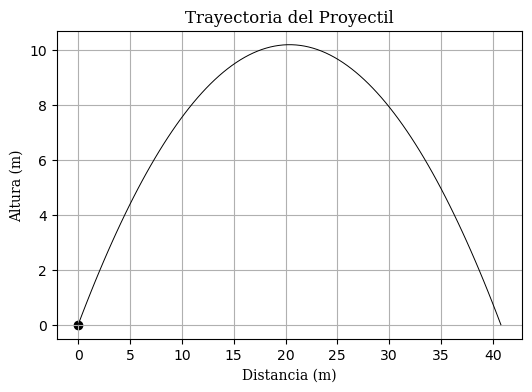

La distancia máxima es: 40.77 m
La altura máxima es: 10.19 m
La velocidad final es: 34.64 m/s


In [15]:
# Condiciones iniciales
theta = 45
yo = 0
xo = 0
vo = 20  # m/s
g = 9.81  # m/s²

# Convertir grados a radianes
conv_grad = np.pi / 180
theta_rad = theta * conv_grad

def grafica(x, y, xo, yo):
    plt.figure(figsize=(6,4))
    plt.plot(x, y, lw=0.7, color='black')
    plt.scatter([xo], [yo], color='black')
    plt.xlabel('Distancia (m)', fontdict={'family': 'serif'}, fontsize=10)
    plt.ylabel('Altura (m)', fontdict={'family': 'serif'}, fontsize=10)
    plt.title('Trayectoria del Proyectil' ,font='serif', fontsize=12)
    plt.grid(True)
    plt.show()

if theta == 0 and yo > 0:  # Tiro horizontal
     # Tiempo para distancia máxima (y=0)
    tmax = np.sqrt(2 * yo / g)
    
    #Tiempo de simulación
    t = np.linspace(0, tmax, 100)
    
    # Posiciones
    x = vo * t + xo
    y = -0.5 * g * t**2 + yo

    # Distancia máxima
    xmax = vo * tmax

    # Velocidad final
    vf = np.sqrt(vo**2 + (g * tmax)**2)

    grafica(x, y, xo, yo)
    print(f'La distancia máxima es: {xmax:.2f} m')
    print(f'La velocidad final es: {vf:.2f} m/s')

elif theta == 90:  # Tiro vertical hacia arriba
    # Tiempo de ascenso
    tascenso = vo / g

    # Tiempo de vuelo total
    ttot = 2 * tascenso

    #Tiempo de simulación
    t = np.linspace(0, ttot, 100)

    # Posiciones
    x = np.zeros(100)
    y = vo * t - 0.5 * g * t**2 + yo

    # Altura máxima
    ymax = yo + vo**2 / (2 * g)

    grafica(x, y, xo, yo)
    print(f'La altura máxima es: {ymax:.2f} m')
    print(f'El tiempo de ascenso es: {tascenso:.2f} s')
    print(f'El tiempo total es: {ttot:.2f} s')

elif theta == -90 or theta == 270:  # Tiro vertical hacia abajo
    # Tiempo de vuelo
    ttot = (-vo + np.sqrt(vo**2 + 2 * g * yo)) / g

    #Tiempo de simulación
    t = np.linspace(0, ttot, 100)
    
    # Posiciones
    x = np.zeros(100)
    y = -vo * t - 0.5 * g * t**2 + yo

    grafica(x, y, xo, yo)
    print(f'El tiempo total es: {ttot:.2f} s')

elif -90 < theta < 90: #Caso general con yo diferente de 0
    # Tiempo para distancia máxima (y=0)
    tmax = (vo * np.sin(theta_rad) + np.sqrt((vo * np.sin(theta_rad))**2 + 2 * g * yo)) / g
    
    #Tiempo de simulación
    t = np.linspace(0, tmax, 100)

    # Posiciones
    x = vo * np.cos(theta_rad) * t + xo
    y = vo * np.sin(theta_rad) * t - 0.5 * g * t**2 + yo
    
    # Distancia máxima
    xmax = xo + vo * np.cos(theta_rad) * tmax
    
    # Altura máxima
    ymax = yo + (vo**2 * np.sin(theta_rad)**2) / (2 * g)
    
    # Velocidad final
    vf = np.sqrt(vo**2 + 2 * g * (xmax - xo))

    grafica(x, y, xo, yo)
    print(f'La distancia máxima es: {xmax:.2f} m') 
    print(f'La altura máxima es: {ymax:.2f} m') 
    print(f'La velocidad final es: {vf:.2f} m/s')

elif -90 < theta < 90 and yo == 0:
    # Tiempo para distancia máxima (y=0)
    tmax = 2 * vo * np.sin(theta_rad) / g
    
    #Tiempo de simulación
    t = np.linspace(0, tmax, 100)
    
    # Posiciones
    x = vo * np.cos(theta_rad) * t + xo
    y = vo * np.sin(theta_rad) * t - 0.5 * g * t**2 + yo
    
    # Distancia máxima
    xmax = (vo**2 * np.sin(2 * theta_rad)) / g
    
    # Altura máxima
    ymax = (vo**2 * np.sin(theta_rad)**2) / (2 * g)
    
    # Velocidad final
    vf = np.sqrt(vo**2 + 2 * g * xmax)

    grafica(x, y, xo, yo)
    print(f'La distancia máxima es: {xmax:.2f} m') 
    print(f'La altura máxima es: {ymax:.2f} m')
    print(f'La velocidad final es: {vf:.2f} m/s')

else:
    print('Condiciones no válidas')

